In [2]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/googleplaystore_preprocessed.csv")
df.head()

,App,Category,Rating,Reviews,Installs,Type,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Price_USD,Size_MB
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159.0,10000.0,Free,Everyone,Art & Design,2018-01-07,1.0.0,4.0.3 and up,0.0,19.0
1,Coloring book moana,ART_AND_DESIGN,3.9,967.0,500000.0,Free,Everyone,Art & Design;Pretend Play,2018-01-15,2.0.0,4.0.3 and up,0.0,14.0
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510.0,5000000.0,Free,Everyone,Art & Design,2018-08-01,1.2.4,4.0.3 and up,0.0,8.7
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644.0,50000000.0,Free,Teen,Art & Design,2018-06-08,Varies with device,4.2 and up,0.0,25.0
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967.0,100000.0,Free,Everyone,Art & Design;Creativity,2018-06-20,1.1,4.4 and up,0.0,2.8


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10358 entries, 0 to 10357
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10358 non-null  str    
 1   Category        10358 non-null  str    
 2   Rating          8892 non-null   float64
 3   Reviews         10357 non-null  float64
 4   Installs        10357 non-null  float64
 5   Type            10357 non-null  str    
 6   Content Rating  10357 non-null  str    
 7   Genres          10358 non-null  str    
 8   Last Updated    10357 non-null  str    
 9   Current Ver     10350 non-null  str    
 10  Android Ver     10355 non-null  str    
 11  Price_USD       10357 non-null  float64
 12  Size_MB         8831 non-null   float64
dtypes: float64(5), str(8)
memory usage: 1.0 MB


In [4]:
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 80)

print("Shape:", df.shape)
print("Exact duplicate rows:", int(df.duplicated().sum()))

profile = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null_count": df.notna().sum(),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_non_null": df.nunique(dropna=True),
}).sort_values("missing_percent", ascending=False)

print(profile)


Shape: (10358, 13)
Exact duplicate rows: 0
                  dtype  non_null_count  missing_count  missing_percent  \
Size_MB         float64            8831           1527            14.74   
Rating          float64            8892           1466            14.15   
Current Ver         str           10350              8             0.08   
Android Ver         str           10355              3             0.03   
Installs        float64           10357              1             0.01   
Content Rating      str           10357              1             0.01   
Last Updated        str           10357              1             0.01   
Reviews         float64           10357              1             0.01   
Type                str           10357              1             0.01   
Price_USD       float64           10357              1             0.01   
App                 str           10358              0             0.00   
Category            str           10358              0   

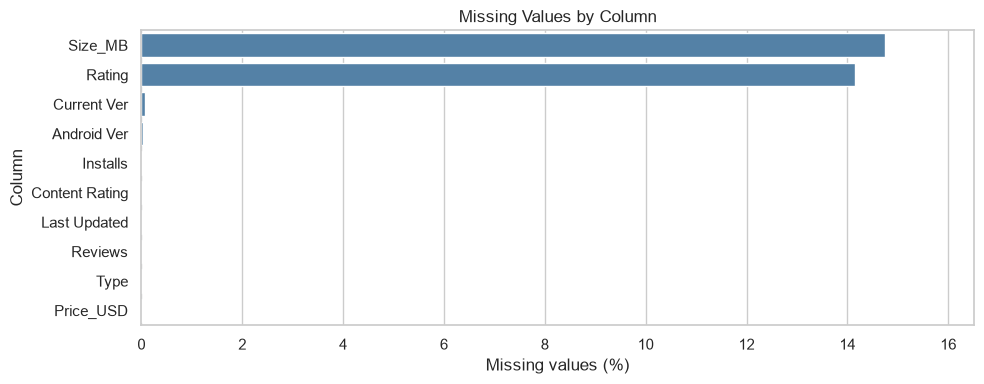

In [5]:
FIGURES_DIR = Path("../reports/figures")
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0]

if not missing_pct.empty:
    plt.figure(figsize=(10, max(4, 0.38 * len(missing_pct))))
    sns.barplot(x=missing_pct.values, y=missing_pct.index, color="steelblue")
    plt.xlabel("Missing values (%)")
    plt.ylabel("Column")
    plt.title("Missing Values by Column")
    plt.xlim(0, min(100, max(5, missing_pct.max() * 1.12)))
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "missing_values_by_column.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()
else:
    print("No missing values found.")


In [6]:
numeric_candidates = [
    column for column in ["Rating", "Reviews", "Installs", "Size_MB", "Price_USD"]
    if column in df.columns
]

if numeric_candidates:
    print(df[numeric_candidates].describe().T)
else:
    print("No expected numeric analysis columns were found.")


             count          mean           std     min     25%       50%  \
Rating      8892.0  4.187877e+00  5.223767e-01  1.0000     4.0       4.3   
Reviews    10357.0  4.059046e+05  2.696778e+06  0.0000    32.0    1680.0   
Installs   10357.0  1.415776e+07  8.023955e+07  0.0000  1000.0  100000.0   
Size_MB     8831.0  2.128779e+01  2.254025e+01  0.0085     4.7      13.0   
Price_USD  10357.0  1.030800e+00  1.627863e+01  0.0000     0.0       0.0   

                 75%           max  
Rating           4.5  5.000000e+00  
Reviews      46416.0  7.815831e+07  
Installs   1000000.0  1.000000e+09  
Size_MB         29.0  1.000000e+02  
Price_USD        0.0  4.000000e+02  


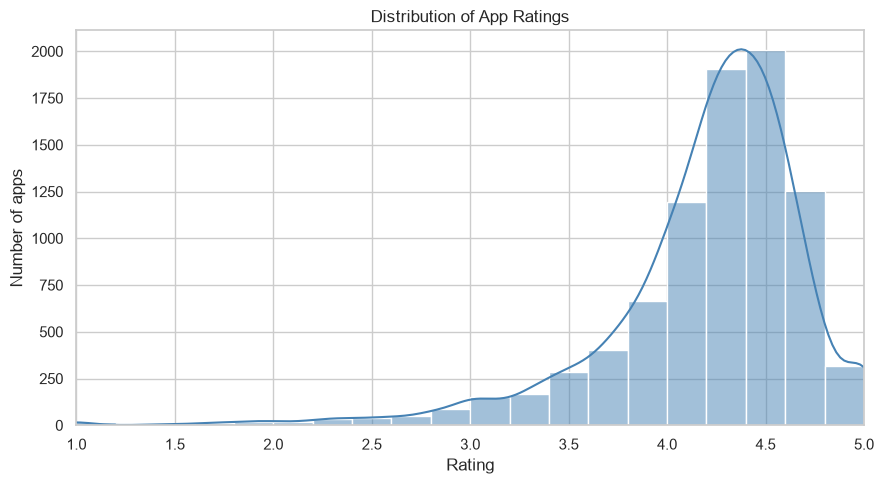

Median rating: 4.30


In [7]:
# App rating distribution
if "Rating" in df.columns:
    ratings = df["Rating"].dropna()
    ratings = ratings[ratings.between(1, 5)]

    if not ratings.empty:
        plt.figure(figsize=(9, 5))
        sns.histplot(ratings, bins=np.arange(1, 5.21, 0.2), kde=True, color="steelblue")
        plt.xlim(1, 5)
        plt.xlabel("Rating")
        plt.ylabel("Number of apps")
        plt.title("Distribution of App Ratings")
        plt.tight_layout()
        plt.savefig(FIGURES_DIR / "rating_distribution.png", dpi=160, bbox_inches="tight")
        plt.show()
        plt.close()
        print(f"Median rating: {ratings.median():.2f}")
    else:
        print("No valid ratings available to plot.")
else:
    print("Rating column not found.")


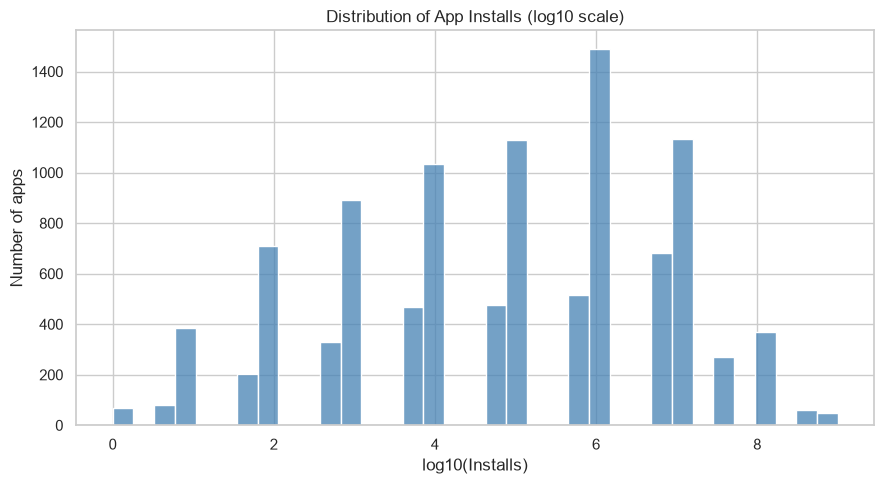

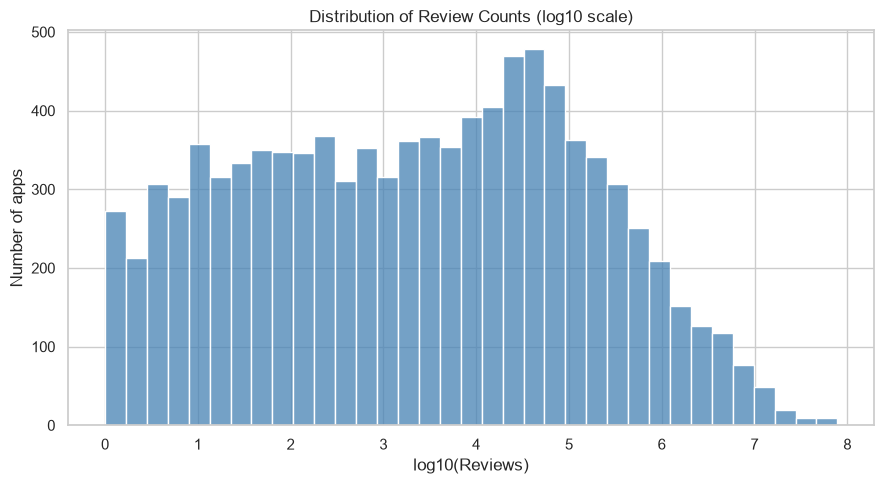

In [8]:
# Installs and reviews: log10 distributions for visualization
for column, title, filename in [
    ("Installs", "Distribution of App Installs (log10 scale)", "installs_distribution_log10.png"),
    ("Reviews", "Distribution of Review Counts (log10 scale)", "reviews_distribution_log10.png"),
]:
    if column not in df.columns:
        continue

    values = df[column].dropna()
    values = values[values >= 0]
    values = values[values > 0]

    if values.empty:
        print(f"No positive values available for {column}.")
        continue

    log_values = np.log10(values)
    plt.figure(figsize=(9, 5))
    sns.histplot(log_values, bins=35, color="steelblue")
    plt.xlabel(f"log10({column})")
    plt.ylabel("Number of apps")
    plt.title(title)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()


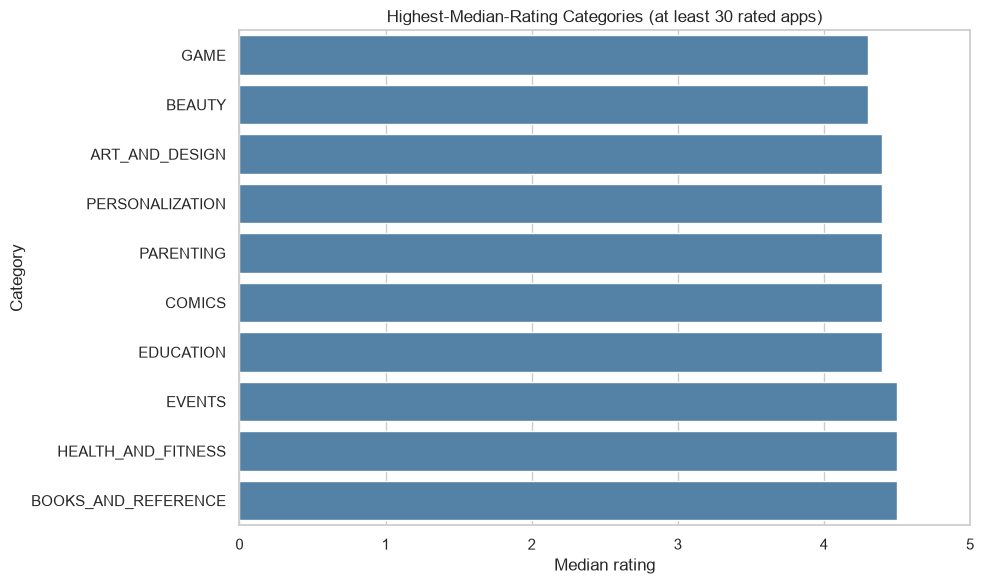

                     median_rating  app_count
Category                                     
BOOKS_AND_REFERENCE            4.5        177
HEALTH_AND_FITNESS             4.5        262
EVENTS                         4.5         45
ART_AND_DESIGN                 4.4         62
COMICS                         4.4         58
EDUCATION                      4.4        129
PERSONALIZATION                4.4        310
PARENTING                      4.4         50
BEAUTY                         4.3         42
GAME                           4.3       1074


In [9]:
if {"Category", "Rating"}.issubset(df.columns):
    category_rating = (
        df.dropna(subset=["Category", "Rating"])
          .groupby("Category")["Rating"]
          .agg(median_rating="median", app_count="count")
          .query("app_count >= 30")
          .sort_values("median_rating", ascending=False)
    )

    if not category_rating.empty:
        top_rated_categories = category_rating.head(10).sort_values("median_rating")

        plt.figure(figsize=(10, 6))
        sns.barplot(
            data=top_rated_categories.reset_index(),
            x="median_rating",
            y="Category",
            color="steelblue"
        )
        plt.xlim(0, 5)
        plt.xlabel("Median rating")
        plt.ylabel("Category")
        plt.title("Highest-Median-Rating Categories (at least 30 rated apps)")
        plt.tight_layout()
        plt.savefig(FIGURES_DIR / "median_rating_by_category.png", dpi=160, bbox_inches="tight")
        plt.show()
        plt.close()

        print(category_rating.head(10))
    else:
        print("Not enough category-rating data for the chosen sample-size threshold.")
else:
    print("Category and/or Rating column not found.")


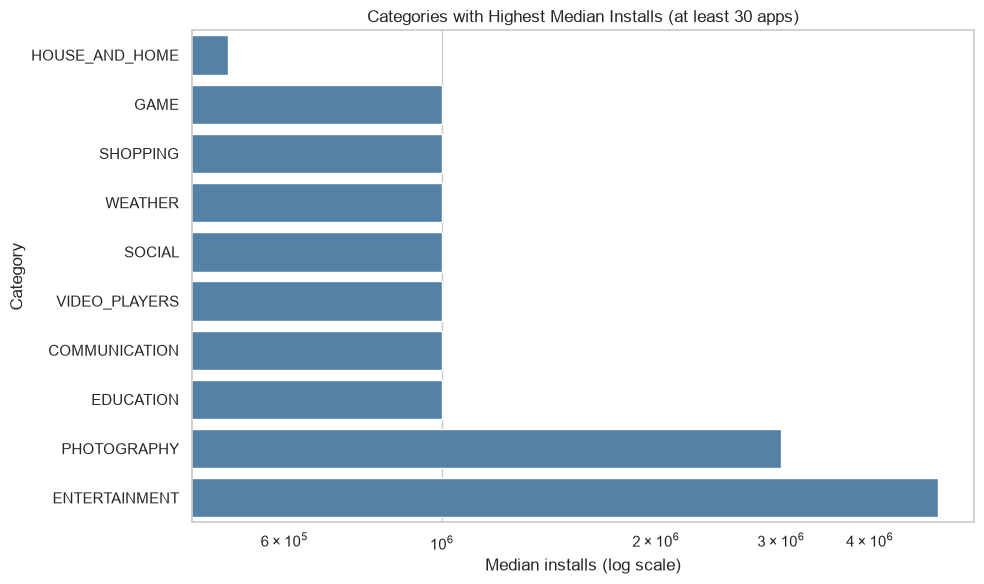

                median_installs  app_count
Category                                  
ENTERTAINMENT         5000000.0        111
PHOTOGRAPHY           3000000.0        322
WEATHER               1000000.0         82
GAME                  1000000.0       1121
EDUCATION             1000000.0        130
SHOPPING              1000000.0        224
SOCIAL                1000000.0        280
VIDEO_PLAYERS         1000000.0        175
COMMUNICATION         1000000.0        366
HOUSE_AND_HOME         500000.0         80


In [10]:
if {"Category", "Installs"}.issubset(df.columns):
    category_installs = (
        df.dropna(subset=["Category", "Installs"])
          .groupby("Category")["Installs"]
          .agg(median_installs="median", app_count="count")
          .query("app_count >= 30")
          .sort_values("median_installs", ascending=False)
    )

    if not category_installs.empty:
        top_install_categories = category_installs.head(10).sort_values("median_installs")

        plt.figure(figsize=(10, 6))
        sns.barplot(
            data=top_install_categories.reset_index(),
            x="median_installs",
            y="Category",
            color="steelblue"
        )
        plt.xscale("log")
        plt.xlabel("Median installs (log scale)")
        plt.ylabel("Category")
        plt.title("Categories with Highest Median Installs (at least 30 apps)")
        plt.tight_layout()
        plt.savefig(FIGURES_DIR / "median_installs_by_category.png", dpi=160, bbox_inches="tight")
        plt.show()
        plt.close()

        print(category_installs.head(10))
    else:
        print("Not enough install data for the chosen sample-size threshold.")
else:
    print("Category and/or Installs column not found.")


      app_count
Type           
Free       9591
Paid        765
<NA>          1
0             1


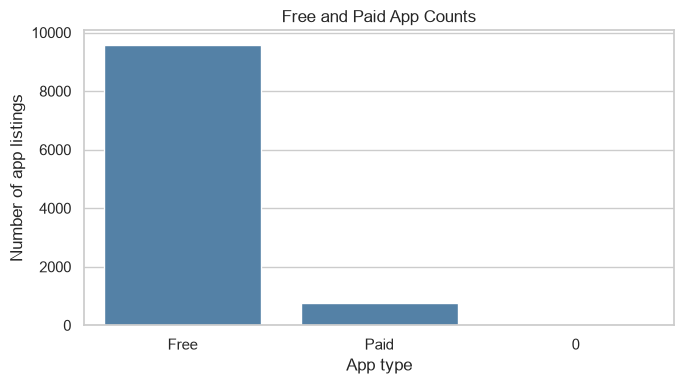

      app_count  Rating  Installs  Reviews  Price_USD
Type                                                 
0             1     NaN       NaN      NaN        NaN
Free       9591     4.3  100000.0   2300.0       0.00
Paid        765     4.4    1000.0     90.0       2.99


In [11]:
if "Type" in df.columns:
    type_clean = df["Type"].astype("string").str.strip().str.title()
    type_counts = type_clean.value_counts(dropna=False)
    print(type_counts.rename("app_count").to_frame())

    plot_counts = type_counts[type_counts.index.notna()]
    if not plot_counts.empty:
        plt.figure(figsize=(7, 4))
        sns.barplot(x=plot_counts.index.astype(str), y=plot_counts.values, color="steelblue")
        plt.xlabel("App type")
        plt.ylabel("Number of app listings")
        plt.title("Free and Paid App Counts")
        plt.tight_layout()
        plt.savefig(FIGURES_DIR / "free_paid_app_counts.png", dpi=160, bbox_inches="tight")
        plt.show()
        plt.close()

    metrics = [column for column in ["Rating", "Installs", "Reviews", "Price_USD"] if column in df.columns]
    if metrics:
        comparison = df.assign(Type=type_clean).groupby("Type")[metrics].median(numeric_only=True)
        counts = df.assign(Type=type_clean).groupby("Type").size().rename("app_count")
        comparison = counts.to_frame().join(comparison)
        print(comparison)
else:
    print("Type column not found.")


Price summary (USD):
          Price_USD
count  10357.000000
mean       1.030800
std       16.278625
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max      400.000000


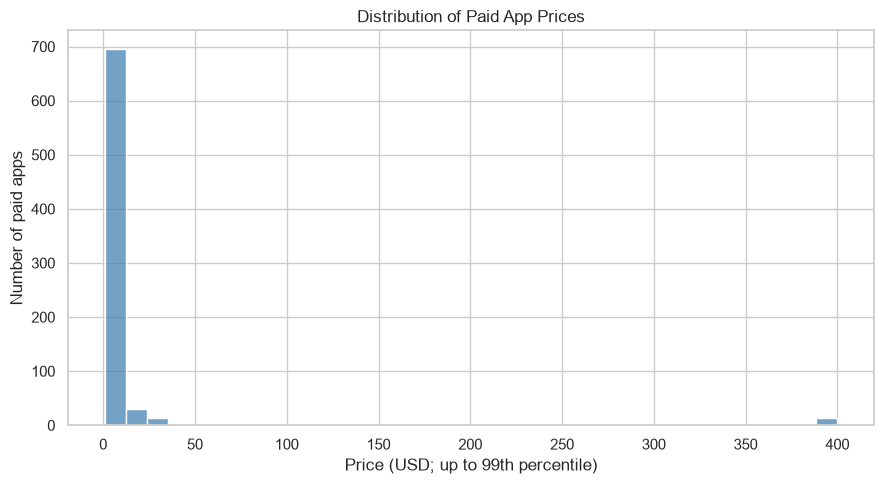

Paid app listings with positive prices: 765
99th percentile of positive prices: $399.99


In [12]:
if "Price_USD" in df.columns:
    prices = df["Price_USD"].dropna()
    print("Price summary (USD):")
    print(prices.describe().to_frame("Price_USD"))

    paid_prices = prices[prices > 0]
    if not paid_prices.empty:
        upper_limit = paid_prices.quantile(0.99)
        plotted_prices = paid_prices[paid_prices <= upper_limit]

        plt.figure(figsize=(9, 5))
        sns.histplot(plotted_prices, bins=35, color="steelblue")
        plt.xlabel("Price (USD; up to 99th percentile)")
        plt.ylabel("Number of paid apps")
        plt.title("Distribution of Paid App Prices")
        plt.tight_layout()
        plt.savefig(FIGURES_DIR / "paid_app_price_distribution.png", dpi=160, bbox_inches="tight")
        plt.show()
        plt.close()

        print(f"Paid app listings with positive prices: {len(paid_prices):,}")
        print(f"99th percentile of positive prices: ${upper_limit:.2f}")
    else:
        print("No positive prices found.")
else:
    print("Price_USD column not found.")


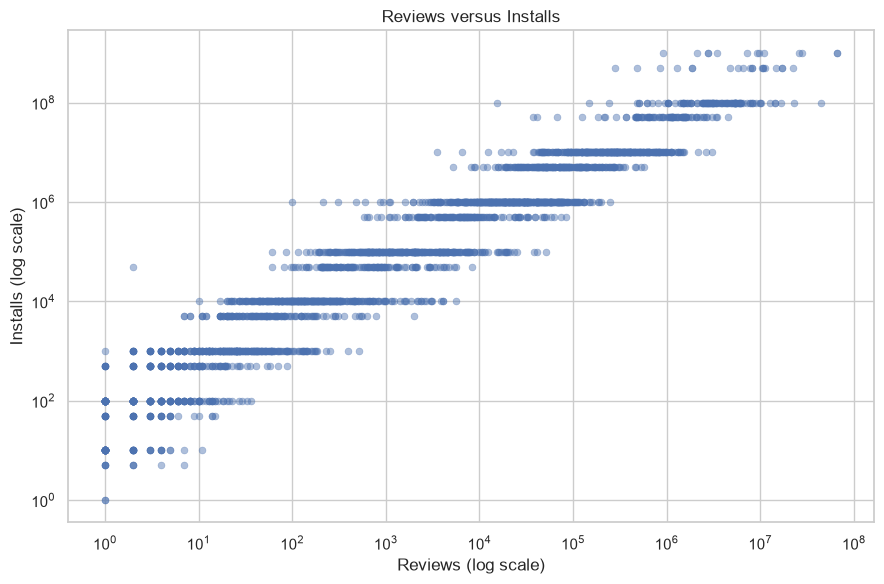

Spearman correlation between Reviews and Installs: 0.971


In [13]:
if {"Reviews", "Installs"}.issubset(df.columns):
    scatter_data = df[["Reviews", "Installs"]].dropna()
    scatter_data = scatter_data[
        (scatter_data["Reviews"] > 0) & (scatter_data["Installs"] > 0)
    ]

    if not scatter_data.empty:
        if len(scatter_data) > 3000:
            scatter_data = scatter_data.sample(n=3000, random_state=42)

        plt.figure(figsize=(9, 6))
        sns.scatterplot(
            data=scatter_data,
            x="Reviews",
            y="Installs",
            alpha=0.45,
            s=25,
            edgecolor=None
        )
        plt.xscale("log")
        plt.yscale("log")
        plt.xlabel("Reviews (log scale)")
        plt.ylabel("Installs (log scale)")
        plt.title("Reviews versus Installs")
        plt.tight_layout()
        plt.savefig(FIGURES_DIR / "reviews_vs_installs.png", dpi=160, bbox_inches="tight")
        plt.show()
        plt.close()

        spearman = df[["Reviews", "Installs"]].corr(method="spearman").iloc[0, 1]
        print(f"Spearman correlation between Reviews and Installs: {spearman:.3f}")
    else:
        print("No positive review/install pairs available.")
else:
    print("Reviews and/or Installs column not found.")


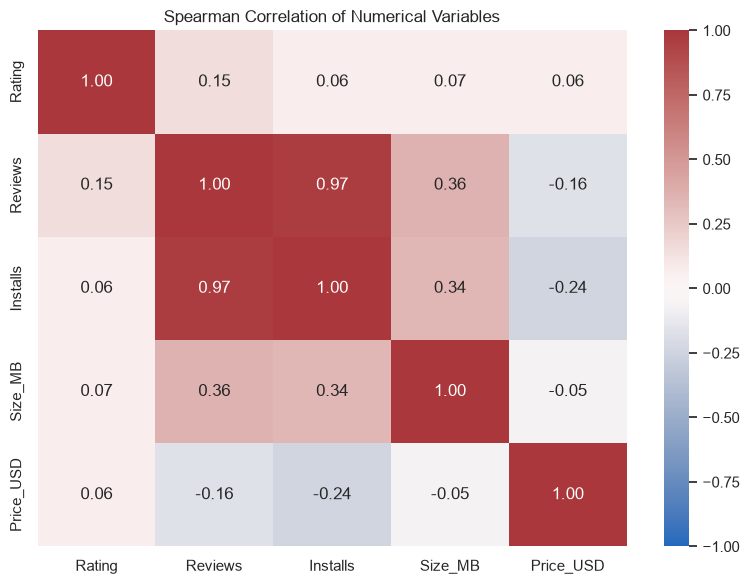

             Rating   Reviews  Installs   Size_MB  Price_USD
Rating     1.000000  0.150491  0.062689  0.068079   0.062640
Reviews    0.150491  1.000000  0.970701  0.360942  -0.164316
Installs   0.062689  0.970701  1.000000  0.341976  -0.239103
Size_MB    0.068079  0.360942  0.341976  1.000000  -0.054696
Price_USD  0.062640 -0.164316 -0.239103 -0.054696   1.000000


In [15]:
correlation_columns = [
    column for column in ["Rating", "Reviews", "Installs", "Size_MB", "Price_USD"]
    if column in df.columns and df[column].notna().sum() > 1
]

if len(correlation_columns) >= 2:
    corr = df[correlation_columns].corr(method="spearman")

    plt.figure(figsize=(8, 6))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1)
    plt.title("Spearman Correlation of Numerical Variables")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "spearman_correlation_heatmap.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

    print(corr)
else:
    print("Not enough numerical columns for a correlation matrix.")


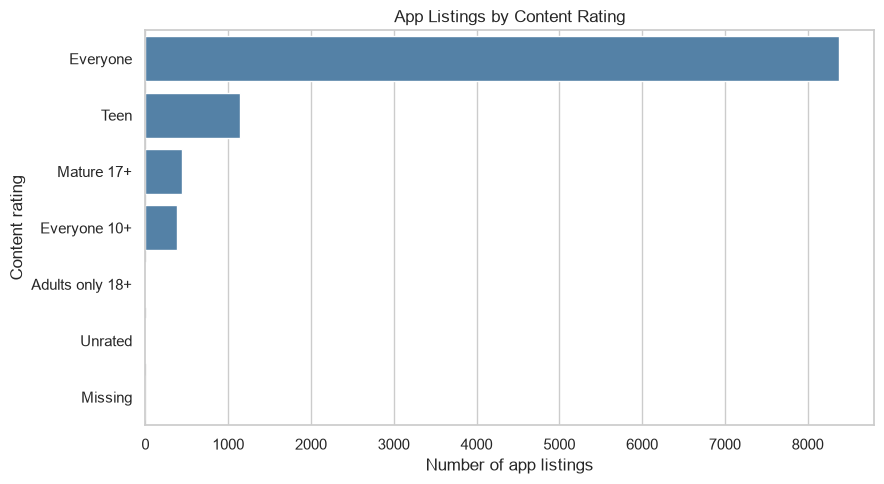

                 app_count
Content Rating            
Everyone              8382
Teen                  1146
Mature 17+             447
Everyone 10+           377
Adults only 18+          3
Unrated                  2
Missing                  1


In [16]:
if "Content Rating" in df.columns:
    content_counts = df["Content Rating"].fillna("Missing").value_counts().head(12)

    plt.figure(figsize=(9, 5))
    sns.barplot(x=content_counts.values, y=content_counts.index, color="steelblue")
    plt.xlabel("Number of app listings")
    plt.ylabel("Content rating")
    plt.title("App Listings by Content Rating")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "content_rating_counts.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

    print(content_counts.rename("app_count").to_frame())
else:
    print("Content Rating column not found.")


In [19]:
summary = {
    "Rows": len(df),
    "Columns": df.shape[1],
    "Exact duplicate rows": int(df.duplicated().sum()),
    "Total missing cells": int(df.isna().sum().sum()),
    "Apps with an app name": int(df["App"].notna().sum()) if "App" in df.columns else None,
    "Distinct categories": int(df["Category"].nunique()) if "Category" in df.columns else None,
}

if "Rating" in df.columns:
    valid_ratings = df["Rating"].dropna()
    valid_ratings = valid_ratings[valid_ratings.between(1, 5)]
    summary["Apps with valid ratings"] = int(valid_ratings.count())
    summary["Median app rating"] = round(float(valid_ratings.median()), 2) if not valid_ratings.empty else None

if "Installs" in df.columns:
    installs = df["Installs"].dropna()
    summary["Apps with install data"] = int(installs.count())
    summary["Median install threshold"] = int(installs.median()) if not installs.empty else None

if "Type" in df.columns:
    type_labels = df["Type"].astype("string").str.strip().str.title()
    non_missing_type_count = int(type_labels.notna().sum())
    if non_missing_type_count:
        summary["Free app share (%)"] = round(
            float(type_labels.eq("Free").sum() / non_missing_type_count * 100), 2
        )

if "Category" in df.columns:
    most_common = df["Category"].value_counts()
    if not most_common.empty:
        summary["Most represented category"] = most_common.index[0]
        summary["Listings in most represented category"] = int(most_common.iloc[0])

print(pd.Series(summary, name="Value").to_frame())


                                        Value
Rows                                    10358
Columns                                    13
Exact duplicate rows                        0
Total missing cells                      3010
Apps with an app name                   10358
Distinct categories                        34
Apps with valid ratings                  8892
Median app rating                         4.3
Apps with install data                  10357
Median install threshold               100000
Free app share (%)                       92.6
Most represented category              FAMILY
Listings in most represented category    1943


Key findings:

1. Dataset coverage and data quality
- The dataset has 10,358 rows and 13 columns.
- It contains 34 distinct app categories and 9,660 distinct app names.
- No exact duplicate rows remain in the analyzed file.
- There are 3,010 missing cells across the dataset.
- Missing values are concentrated in:
  - Size_MB: 1,527 missing values (14.74%)
  - Rating: 1,466 missing values (14.15%)
- Other missingness is comparatively small: Current Ver has 8 missing values; Android Ver has 3; and Reviews, Installs, Type, Content Rating, Last Updated, and Price_USD each have 1 missing value.
- The Type column includes one unexpected value, 0, in addition to one missing value. This record should be inspected before relying on free-versus-paid comparisons.
Implication: Treat missingness as a material limitation for analyses of ratings and app size. Avoid filling missing ratings or sizes with arbitrary values.

2. App ratings are generally high
- There are 8,892 non-missing ratings.
- The median app rating is 4.3, and the mean is approximately 4.19.
- The interquartile range runs from 4.0 (25th percentile) to 4.5 (75th percentile).
- In the category comparison, which includes categories with at least 30 rated apps, Books & Reference and Health & Fitness have the highest reported median rating of 4.5. Events also has a median of 4.5, based on 45 rated apps.
Implication: Ratings are concentrated toward the upper end of the scale. Category-level medians are more useful when read alongside the number of rated apps; they do not establish that a category causes higher satisfaction.

3. App popularity is highly skewed
- The median install threshold is 100,000, while the mean is approximately 14.16 million.
- The maximum recorded install threshold is 1 billion.
- The gap between the mean and median indicates a long right tail: a relatively small number of very popular apps pull the mean upward.
- Installs values were converted from source labels such as 100,000+. They represent displayed thresholds, not necessarily exact install counts.
The highest median install thresholds among categories with at least 30 observations are:
Category	Median install threshold	App count
Entertainment	5,000,000	111
Photography	3,000,000	322
Weather	1,000,000	82
Game	1,000,000	1,121
Education	1,000,000	130
Shopping	1,000,000	224
Social	1,000,000	280
Video Players	1,000,000	175
Communication	1,000,000	366
Implication: Median install thresholds and log-scale charts describe popularity better than raw means alone. Interpret category comparisons as approximate because installs are bucketed in the source.

4. The dataset is dominated by free apps
- 9,591 listings are labelled Free and 765 are labelled Paid.
- Among records labelled Free or Paid, approximately 92.6% are Free.
- The median values by app type are:
Metric	Free apps	Paid apps
Median rating	4.3	4.4
Median install threshold	100,000	1,000
Median review count	2,300	90
Median price	$0.00	$2.99
The paid-app sample is much smaller than the free-app sample. The small difference in median rating should not be interpreted as proof that paid apps are better, and the median installs/reviews are descriptive rather than causal comparisons.

5. Most listed apps are classified as suitable for everyone
The Content Rating counts are:
- Everyone: 8,382 listings
- Teen: 1,146
- Mature 17+: 447
- Everyone 10+: 377
- Adults only 18+: 3
- Unrated: 2
- Missing: 1
Implication: Everyone is by far the most common content-rating group in this dataset. This describes the dataset's listings and labels; it does not independently verify the appropriateness of individual apps.

6. Price values are heavily concentrated at zero, with a high-priced tail
- The median price is $0.00, and the 75th percentile is also $0.00, consistent with the large share of free apps.
- The dataset contains 765 positive-price listings.
- The maximum recorded price is $400.00; the reported 99th percentile among positive prices is $399.99.
Implication: The overall mean price of approximately $1.03 is not representative of a typical listing because most apps are free and a small number of high-priced apps affect the distribution. Verify extreme prices before using them in a business recommendation; do not delete them solely because they are high.

7. Reviews and installs move closely together
- The Spearman correlation between Reviews and Installs is 0.971, a very strong positive monotonic association.
- In the Spearman correlation matrix:
  - Rating vs. Reviews: 0.150
  - Rating vs. Installs: 0.063
  - Reviews vs. Price_USD: -0.164
  - Installs vs. Price_USD: -0.239
Implication: Apps with higher install thresholds generally also have more reviews. Ratings show only weak associations with installs and reviews in this dataset. Correlation does not imply causation, and the install thresholds limit precision.

8. App sizes have material missingness and a wide range
- Size_MB has 8,831 non-missing values and 1,527 missing values (14.74%).
- The median recorded size is 13 MB.
- The 25th and 75th percentiles are 4.7 MB and 29 MB, respectively; the maximum is 100 MB.
Implication: The median is a more robust description of a typical recorded app size than the mean. Since missingness is substantial, this summary applies only to rows with a recorded size.